> **v2.2 corrected derivative — typed reference, not a handwritten trace.** Copy of `Knapsack_Trace_Joan.ipynb` (kept unchanged alongside this file) with the typed Markdown narrative corrected in the Network Audit v2.2 refinement: the outdated claim that "5 of 6 offices meet the 20-minute promise" is replaced by the direct-transfer / local-fulfilment / outside-plan breakdown, and "promise" is worded as the proposed 20-minute internal hub-to-branch transfer target. All code cells, outputs and the three embedded figures are unchanged (verified byte-for-byte by `tools/make_joan_v2_2_reference.py`). The figures' own titles (e.g. "yearly benefit") are part of the original images and were not edited.

# Knapsack trace: Tab 3 (Investment)
**Emirates Post Network Audit · Design and Analysis of Algorithms (MAIB)**
**Investment Analyst: Joan**

**Question.** With a first-year budget of **AED 450,000** (set by Joan), which upgrades should Emirates Post fund for the offices outside the proposed 20-minute internal hub-to-branch transfer target from the Al Ramool hub, so that the modelled annual gross-benefit proxy is as large as possible?

**Method.** A 0/1 knapsack solved by dynamic programming, traced cell by cell in code. It is then compared with the greedy rule "best benefit per AED first".

| Step | What this notebook does |
|---|---|
| 0 | Dijkstra from the hub: which offices are outside the 20-minute internal transfer target (same as Tab 2) |
| 1 | The four upgrade options and the budget, converted to AED 10,000 units |
| 2 | Fill the knapsack grid one cell at a time, printing every decision |
| 3 | Traceback: which upgrades were chosen |
| 4 | Greedy, step by step, and the gap |
| 5 | Exact check in AED + brute force over every combination |
| 6 | Graphs: the grid with the traceback path, and DP vs greedy across every budget |

Run all cells: **Runtime → Run all**. Nothing needs uploading; the data is in the notebook. Change `BUDGET_AED` in Step 1 and run again to test another budget.

In [1]:
from heapq import heappush, heappop
from itertools import combinations
from functools import reduce
from math import gcd, inf
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 60)

## Step 0: Which offices are outside the 20-minute internal transfer target? (Dijkstra, as in Tab 2)
These are the 13 van routes that survive the Data Lead's threshold X = 38 min. Drive times come from Google Maps, Thursday 07:00, and are used in both directions.

In [2]:
HUB, PROMISE = "HUB", 20          # minutes
routes = [("HUB","KAR",13),("HUB","QUS",16),("KAR","UMS",20),("HUB","UMS",23),("HUB","SHJ",24),
          ("UMS","JAF",24),("KAR","QUS",25),("SHJ","AJM",27),("QUS","SHJ",29),("KAR","SHJ",30),
          ("QUS","UMS",32),("KAR","JAF",34),("QUS","AJM",37)]

def dijkstra(routes, hub):
    adj = {}
    for a, b, m in routes:
        adj.setdefault(a, []).append((b, m)); adj.setdefault(b, []).append((a, m))
    dist = {n: inf for n in adj}; dist[hub] = 0
    heap, done = [(0, hub)], set()
    while heap:
        d, u = heappop(heap)
        if u in done: continue
        done.add(u)
        for v, w in adj[u]:
            if d + w < dist[v]:
                dist[v] = d + w; heappush(heap, (dist[v], v))
    return dist

times = dijkstra(routes, HUB)
pd.DataFrame([{"Office": o, "Fastest time (min)": t, "Status at 20 min": "PASS" if t <= PROMISE else "FAIL"}
              for o, t in sorted(times.items(), key=lambda x: x[1]) if o != HUB])

,Office,Fastest time (min),Status at 20 min
0,KAR,13,PASS
1,QUS,16,PASS
2,UMS,23,FAIL
3,SHJ,24,FAIL
4,JAF,47,FAIL
5,AJM,51,FAIL


Four offices are outside the target: **UMS (23), SHJ (24), JAF (47), AJM (51)**. Each one gets one upgrade option.

## Step 1: Upgrade options and budget
Costs are **first-year** AED (set-up plus 12 months running). Benefits are a modelled annual gross-benefit proxy (estimated gross fee/revenue opportunity per year) — not net profit, cash flow or ROI. Rows follow the group's matrix order: UMS, JAF, SHJ, AJM.

| Upgrade | How the cost was built | Why the benefit |
|---|---|---|
| UMS express motorbike | scooter 9,900 + rider 54,000 + running 6,000 | about 15 Express orders/day × AED 30 × 300 days |
| JAF mini-hub | 1,200 sq ft × AED 40 + 20% JAFZA fee + agency + fit-out 15,000 + storekeeper 51,120 + night restock 15,000 | about 8 Premium B2B shipments/day × AED 150 × 300 days |
| SHJ mini-hub | 1,200 sq ft × AED 40 + agency + fit-out + storekeeper + night restock 12,000 | about 25 Express orders/day × AED 30 × 300 days |
| AJM mini-hub | 1,200 sq ft × AED 45 + agency + fit-out + storekeeper + night restock 12,000 | about 20 Express orders/day × AED 30 × 300 days |

The trace uses **AED 10,000 units** (costs rounded to the nearest unit) so the grid has 46 columns. Step 5 repeats the calculation in exact AED and confirms the same answer.

In [3]:
BUDGET_AED = 450_000              # first-year budget, decided by Joan (Investment Analyst)
UNIT = 10_000                     # AED per grid unit for the trace

names    = ["UMS", "JAF", "SHJ", "AJM"]
upgrades = ["Express motorbike courier", "JAFZA mini-hub", "Sharjah mini-hub", "Ajman mini-hub"]
cost_aed = [69_900, 143_520, 130_920, 137_520]
ben_aed  = [135_000, 360_000, 225_000, 180_000]

costs    = [round(c / UNIT) for c in cost_aed]       # grid units
benefits = [b // 1000 for b in ben_aed]              # AED '000 (cell values)
B        = BUDGET_AED // UNIT                        # budget in units

pd.DataFrame({"Row": range(1, 5), "Office": names, "Upgrade": upgrades,
              "Cost (AED)": [f"{c:,}" for c in cost_aed], "Cost (units)": costs,
              "Benefit (AED/yr)": [f"{b:,}" for b in ben_aed], "Benefit (AED '000)": benefits,
              "Benefit per AED": [round(b / c, 2) for b, c in zip(ben_aed, cost_aed)]})

,Row,Office,Upgrade,Cost (AED),Cost (units),Benefit (AED/yr),Benefit (AED '000),Benefit per AED
0,1,UMS,Express motorbike courier,"69,900",7,"135,000",135,1.93
1,2,JAF,JAFZA mini-hub,"143,520",14,"360,000",360,2.51
2,3,SHJ,Sharjah mini-hub,"130,920",13,"225,000",225,1.72
3,4,AJM,Ajman mini-hub,"137,520",14,"180,000",180,1.31


In [4]:
print(f"Budget: AED {BUDGET_AED:,} = {B} units.  All four together: AED {sum(cost_aed):,} = {sum(costs)} units.")
print("The budget cannot fund all four, so the knapsack has a real choice to make.")

Budget: AED 450,000 = 45 units.  All four together: AED 481,860 = 48 units.
The budget cannot fund all four, so the knapsack has a real choice to make.


## Step 2: Fill the grid, one cell at a time
`K[i][w]` = the best benefit using only the first *i* upgrades with a budget of *w* units. Row 0 is all zeros. For every other cell:

- if cost<sub>i</sub> > w: **cannot afford** it, so `K[i][w] = K[i-1][w]`
- otherwise: `K[i][w] = max( K[i-1][w]` *(leave)*`, benefit_i + K[i-1][w - cost_i]` *(take)* `)`

The log below prints the decision for every cell, the same way it would be written by hand.

In [5]:
n = len(costs)
K = [[0] * (B + 1) for _ in range(n + 1)]
log = []
for i in range(1, n + 1):
    c, b = costs[i-1], benefits[i-1]
    for w in range(B + 1):
        leave = K[i-1][w]
        if c > w:
            K[i][w] = leave
            log.append((i, names[i-1], w, leave, None, leave, "cannot afford"))
        else:
            take = b + K[i-1][w - c]
            K[i][w] = max(leave, take)
            decision = "take" if take > leave else ("leave" if leave > take else "tie (leave)")
            log.append((i, names[i-1], w, leave, f"{b} + K[{i-1}][{w-c}]={K[i-1][w-c]} -> {take}", K[i][w], decision))

trace = pd.DataFrame(log, columns=["i", "Upgrade", "w", "Leave = K[i-1][w]", "Take = b + K[i-1][w-c]", "K[i][w]", "Decision"])
for i in range(1, n + 1):
    first_take = trace[(trace.i == i) & (trace.Decision == "take")].w.min()
    print(f"Row {i} ({names[i-1]}, cost {costs[i-1]}, benefit {benefits[i-1]}): affordable from w = {costs[i-1]}; "
          f"'take' wins first at w = {first_take}")
print(f"\n{len(trace)} cells filled. Every cell where the decision changes the value:")
trace[trace.Decision == "take"].reset_index(drop=True)

Row 1 (UMS, cost 7, benefit 135): affordable from w = 7; 'take' wins first at w = 7
Row 2 (JAF, cost 14, benefit 360): affordable from w = 14; 'take' wins first at w = 14
Row 3 (SHJ, cost 13, benefit 225): affordable from w = 13; 'take' wins first at w = 13
Row 4 (AJM, cost 14, benefit 180): affordable from w = 14; 'take' wins first at w = 41

184 cells filled. Every cell where the decision changes the value:


,i,Upgrade,w,Leave = K[i-1][w],Take = b + K[i-1][w-c],K[i][w],Decision
0,1,UMS,7,0,135 + K[0][0]=0 -> 135,135,take
1,1,UMS,8,0,135 + K[0][1]=0 -> 135,135,take
2,1,UMS,9,0,135 + K[0][2]=0 -> 135,135,take
3,1,UMS,10,0,135 + K[0][3]=0 -> 135,135,take
4,1,UMS,11,0,135 + K[0][4]=0 -> 135,135,take
...,...,...,...,...,...,...,...
91,4,AJM,41,720,180 + K[3][27]=585 -> 765,765,take
92,4,AJM,42,720,180 + K[3][28]=585 -> 765,765,take
93,4,AJM,43,720,180 + K[3][29]=585 -> 765,765,take
94,4,AJM,44,720,180 + K[3][30]=585 -> 765,765,take


In [6]:
# the full cell-by-cell log (184 cells), for the working tab
with pd.option_context("display.max_rows", 200):
    display(trace)

,i,Upgrade,w,Leave = K[i-1][w],Take = b + K[i-1][w-c],K[i][w],Decision
0,1,UMS,0,0,NaN,0,cannot afford
1,1,UMS,1,0,NaN,0,cannot afford
2,1,UMS,2,0,NaN,0,cannot afford
3,1,UMS,3,0,NaN,0,cannot afford
4,1,UMS,4,0,NaN,0,cannot afford
5,1,UMS,5,0,NaN,0,cannot afford
6,1,UMS,6,0,NaN,0,cannot afford
7,1,UMS,7,0,135 + K[0][0]=0 -> 135,135,take
8,1,UMS,8,0,135 + K[0][1]=0 -> 135,135,take
9,1,UMS,9,0,135 + K[0][2]=0 -> 135,135,take


In [7]:
grid = pd.DataFrame(K, index=["0 (none)"] + [f"{i} {nm} (c={c}, b={b})" for i, (nm, c, b) in
                                            enumerate(zip(names, costs, benefits), 1)])
grid.columns.name = "w (units of AED 10,000)"
print(f"The completed grid (cells in AED '000). Bottom-right K[{n}][{B}] = {K[n][B]}")
grid

The completed grid (cells in AED '000). Bottom-right K[4][45] = 765


"w (units of AED 10,000)",0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45
0 (none),0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
"1 UMS (c=7, b=135)",0,0,0,0,0,0,0,135,135,135,135,135,135,135,135,135,135,135,135,135,135,135,135,135,135,135,135,135,135,135,135,135,135,135,135,135,135,135,135,135,135,135,135,135,135,135
"2 JAF (c=14, b=360)",0,0,0,0,0,0,0,135,135,135,135,135,135,135,360,360,360,360,360,360,360,495,495,495,495,495,495,495,495,495,495,495,495,495,495,495,495,495,495,495,495,495,495,495,495,495
"3 SHJ (c=13, b=225)",0,0,0,0,0,0,0,135,135,135,135,135,135,225,360,360,360,360,360,360,360,495,495,495,495,495,495,585,585,585,585,585,585,585,720,720,720,720,720,720,720,720,720,720,720,720
"4 AJM (c=14, b=180)",0,0,0,0,0,0,0,135,135,135,135,135,135,225,360,360,360,360,360,360,360,495,495,495,495,495,495,585,585,585,585,585,585,585,720,720,720,720,720,720,720,765,765,765,765,765


## Step 3: Traceback
Start at the bottom-right cell. If a cell **differs** from the one directly above it, that upgrade was taken: move left by its cost. If it is the same, the upgrade was left.

In [8]:
chosen, w, path = [], B, []
for i in range(n, 0, -1):
    took = K[i][w] != K[i-1][w]
    path.append((i, w))
    if took:
        print(f"K[{i}][{w}] = {K[i][w]}  !=  K[{i-1}][{w}] = {K[i-1][w]}  ->  TAKE {names[i-1]:<4}  w = {w} - {costs[i-1]} = {w - costs[i-1]}")
        chosen.append(i - 1); w -= costs[i-1]
    else:
        print(f"K[{i}][{w}] = {K[i][w]}  ==  K[{i-1}][{w}] = {K[i-1][w]}  ->  leave {names[i-1]}")
chosen.reverse()
dp_cost = sum(cost_aed[i] for i in chosen)
print(f"\nDP chooses: {' + '.join(names[i] for i in chosen)}")
print(f"Benefit {K[n][B]}k = AED {sum(ben_aed[i] for i in chosen):,}/yr · spend AED {dp_cost:,} · left AED {BUDGET_AED - dp_cost:,}")

K[4][45] = 765  !=  K[3][45] = 720  ->  TAKE AJM   w = 45 - 14 = 31
K[3][31] = 585  !=  K[2][31] = 495  ->  TAKE SHJ   w = 31 - 13 = 18
K[2][18] = 360  !=  K[1][18] = 135  ->  TAKE JAF   w = 18 - 14 = 4
K[1][4] = 0  ==  K[0][4] = 0  ->  leave UMS

DP chooses: JAF + SHJ + AJM
Benefit 765k = AED 765,000/yr · spend AED 411,960 · left AED 38,040


## Step 4: Greedy comparison
Sort the upgrades by benefit per AED, highest first. Then take each one that still fits in the money left.

In [9]:
order = sorted(range(n), key=lambda i: (-ben_aed[i] / cost_aed[i], i))
left, g_total, g_picks = B, 0, []
for i in order:
    fits = costs[i] <= left
    if fits:
        left -= costs[i]; g_total += benefits[i]; g_picks.append(i)
    print(f"{names[i]:<4} ratio {ben_aed[i]/cost_aed[i]:.2f}  cost {costs[i]:>2}  {'fits ' if fits else 'NO   '}  units left {left}")
g_cost = sum(cost_aed[i] for i in g_picks)
print(f"\nGreedy chooses: {' + '.join(names[i] for i in g_picks)} = {g_total}k (AED {g_total*1000:,}/yr), spend AED {g_cost:,}")
print(f"DP chooses:     {' + '.join(names[i] for i in chosen)} = {K[n][B]}k (AED {K[n][B]*1000:,}/yr), spend AED {dp_cost:,}")
print(f"\nGreedy loses AED {(K[n][B] - g_total)*1000:,} a year." if K[n][B] > g_total else "\nGreedy and DP agree at this budget.")

JAF  ratio 2.51  cost 14  fits   units left 31
UMS  ratio 1.93  cost  7  fits   units left 24
SHJ  ratio 1.72  cost 13  fits   units left 11
AJM  ratio 1.31  cost 14  NO     units left 11

Greedy chooses: JAF + UMS + SHJ = 720k (AED 720,000/yr), spend AED 344,340
DP chooses:     JAF + SHJ + AJM = 765k (AED 765,000/yr), spend AED 411,960

Greedy loses AED 45,000 a year.


Why greedy loses: it takes JAF first (the best ratio) and then the cheap UMS motorbike. That leaves 11 units, which is too little for a 14-unit mini-hub. The DP sees that skipping UMS lets two mini-hubs fit.

## Step 5: Exact check (no rounding) + brute force
The same DP run in exact money units: the largest unit that divides every cost and the budget, which is AED 60 here. Then every one of the 2⁴ = 16 combinations is tried as a cross-check.

In [10]:
def knapsack(c, b, W):
    K = [[0] * (W + 1) for _ in range(len(c) + 1)]
    for i in range(1, len(c) + 1):
        for w in range(W + 1):
            K[i][w] = K[i-1][w]
            if c[i-1] <= w:
                K[i][w] = max(K[i][w], b[i-1] + K[i-1][w - c[i-1]])
    ch, w = [], W
    for i in range(len(c), 0, -1):
        if K[i][w] != K[i-1][w]:
            ch.append(i-1); w -= c[i-1]
    return K, K[-1][W], sorted(ch)

def greedy(c, b, W):
    left, tot, picks = W, 0, []
    for i in sorted(range(len(c)), key=lambda i: (-b[i] / c[i], i)):
        if c[i] <= left:
            left -= c[i]; tot += b[i]; picks.append(i)
    return tot, sorted(picks)

u = reduce(gcd, cost_aed + [BUDGET_AED])
ce, We = [c // u for c in cost_aed], BUDGET_AED // u
_, exact_best, exact_ch = knapsack(ce, ben_aed, We)
best_bf = max((sum(ben_aed[i] for i in s), s) for r in range(n + 1) for s in combinations(range(n), r)
              if sum(cost_aed[i] for i in s) <= BUDGET_AED)
print(f"Exact unit AED {u}: DP chooses {' + '.join(names[i] for i in exact_ch)} = AED {exact_best:,}/yr")
print(f"Brute force:          best = AED {best_bf[0]:,}/yr with {' + '.join(names[i] for i in best_bf[1])}")
print(f"Same as the AED 10,000 trace: {sorted(exact_ch) == sorted(chosen)} · brute force agrees: {best_bf[0] == exact_best}")

Exact unit AED 60: DP chooses JAF + SHJ + AJM = AED 765,000/yr
Brute force:          best = AED 765,000/yr with JAF + SHJ + AJM
Same as the AED 10,000 trace: True · brute force agrees: True


## Step 6: Graphs
### Graph 1: the knapsack grid, with the traceback path outlined

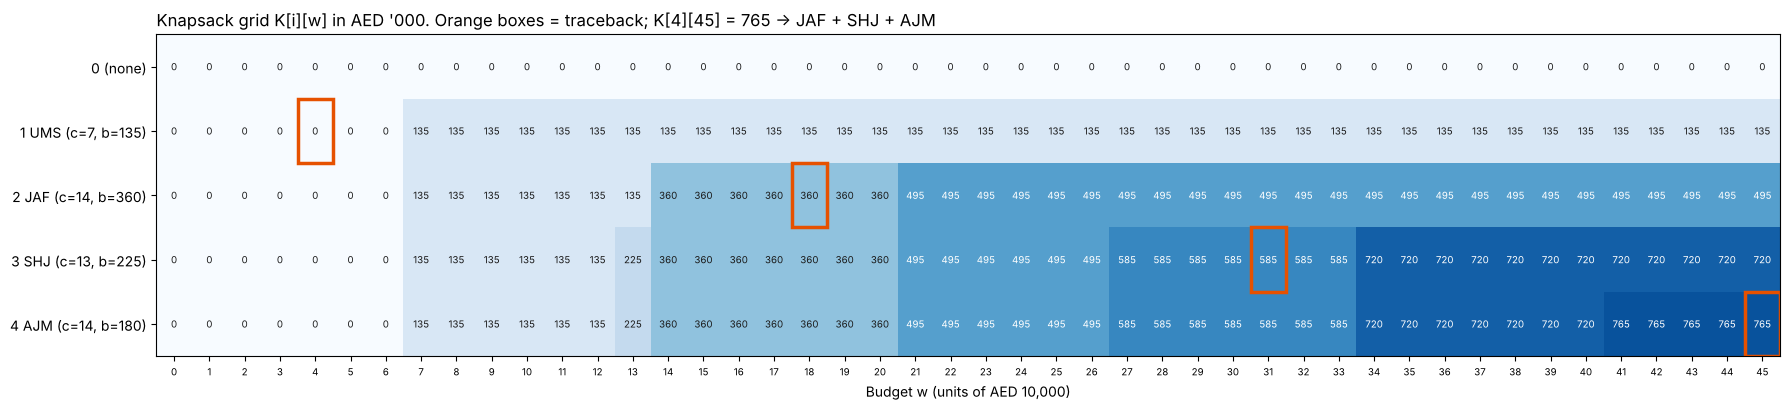

In [11]:
fig, ax = plt.subplots(figsize=(18, 4.2))
ax.imshow(K, aspect="auto", cmap="Blues", vmin=0, vmax=max(map(max, K)) * 1.15)
for i in range(n + 1):
    for w in range(B + 1):
        ax.text(w, i, K[i][w], ha="center", va="center", fontsize=7,
                color="white" if K[i][w] > 0.6 * K[n][B] else "#1a1a1a")
for i, w in path:
    ax.add_patch(Rectangle((w - 0.5, i - 0.5), 1, 1, fill=False, edgecolor="#E65100", linewidth=2.5))
ax.set_yticks(range(n + 1)); ax.set_yticklabels(grid.index)
ax.set_xticks(range(0, B + 1, 1)); ax.tick_params(axis="x", labelsize=7)
ax.set_xlabel("Budget w (units of AED 10,000)")
ax.set_title(f"Knapsack grid K[i][w] in AED '000. Orange boxes = traceback; K[{n}][{B}] = {K[n][B]} "
             f"→ {' + '.join(names[i] for i in chosen)}", loc="left")
plt.tight_layout(); plt.show()

### Graph 2: DP vs greedy at every budget from AED 0 to 600,000

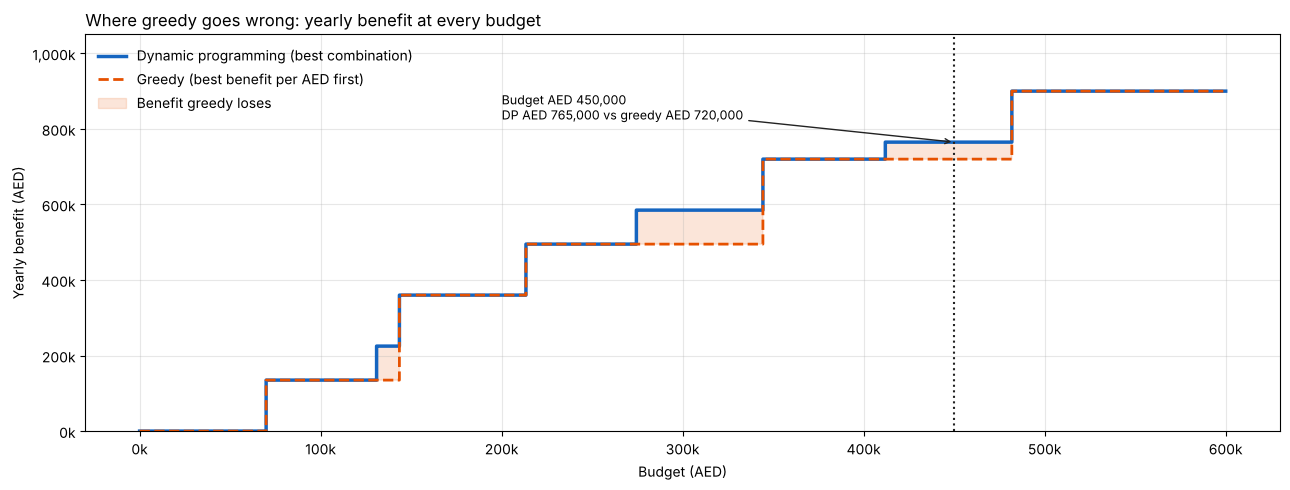

Budgets where greedy earns less than DP:
  AED 130,920 to 143,500  (up to AED 90,000 a year lost)
  AED 274,440 to 344,320  (up to AED 90,000 a year lost)
  AED 411,960 to 481,840  (up to AED 45,000 a year lost)


In [12]:
MAX_AED = 600_000
u2 = reduce(gcd, cost_aed + [10_000])
c2, W2 = [c // u2 for c in cost_aed], MAX_AED // u2
Kfull, _, _ = knapsack(c2, ben_aed, W2)             # last row = DP best at every budget
budgets = [w * u2 for w in range(W2 + 1)]
dp_best = Kfull[-1]
gr_best = [greedy(c2, ben_aed, w)[0] for w in range(W2 + 1)]

fig, ax = plt.subplots(figsize=(13, 5))
ax.step(budgets, dp_best, where="post", color="#1565C0", lw=2.5, label="Dynamic programming (best combination)")
ax.step(budgets, gr_best, where="post", color="#E65100", lw=2, ls="--", label="Greedy (best benefit per AED first)")
ax.fill_between(budgets, gr_best, dp_best, step="post", where=[d > g for d, g in zip(dp_best, gr_best)],
                color="#E65100", alpha=0.15, label="Benefit greedy loses")
ax.axvline(BUDGET_AED, color="#222", ls=":", lw=1.5)
ax.annotate(f"Budget AED {BUDGET_AED:,}\nDP AED {exact_best:,} vs greedy AED {g_total*1000:,}",
            xy=(BUDGET_AED, exact_best), xytext=(BUDGET_AED - 250_000, exact_best + 60_000),
            arrowprops=dict(arrowstyle="->", color="#222"), fontsize=9)
ax.set_xlabel("Budget (AED)"); ax.set_ylabel("Yearly benefit (AED)")
ax.xaxis.set_major_formatter(lambda x, _: f"{x/1000:,.0f}k"); ax.yaxis.set_major_formatter(lambda y, _: f"{y/1000:,.0f}k")
ax.set_ylim(0, 1_050_000); ax.grid(alpha=0.3); ax.legend(loc="upper left", frameon=False)
ax.set_title("Where greedy goes wrong: yearly benefit at every budget", loc="left")
plt.tight_layout(); plt.show()

ranges, start = [], None
for b, d, g in zip(budgets, dp_best, gr_best):
    if d > g and start is None: start, worst = b, 0
    if d > g: worst = max(worst, d - g)
    if d <= g and start is not None: ranges.append((start, prev, worst)); start = None
    prev = b
if start is not None: ranges.append((start, prev, worst))
print("Budgets where greedy earns less than DP:")
for a, z, gap in ranges:
    print(f"  AED {a:,} to {z:,}  (up to AED {gap:,} a year lost)")

### Graph 3: what each plan funds at the chosen budget

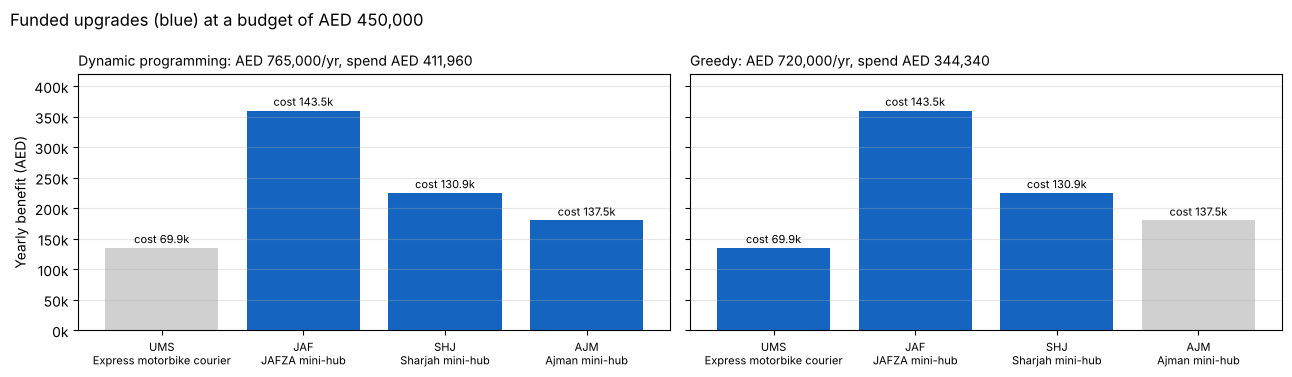

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for ax, (title, picks, total) in zip(axes, [("Dynamic programming", exact_ch, exact_best),
                                           ("Greedy", g_picks, g_total * 1000)]):
    cols = ["#1565C0" if i in picks else "#D0D0D0" for i in range(n)]
    ax.bar([f"{nm}\n{up}" for nm, up in zip(names, upgrades)], ben_aed, color=cols)
    for i in range(n):
        ax.text(i, ben_aed[i] + 8000, f"cost {cost_aed[i]/1000:,.1f}k", ha="center", fontsize=8)
    spent = sum(cost_aed[i] for i in picks)
    ax.set_title(f"{title}: AED {total:,}/yr, spend AED {spent:,}", loc="left", fontsize=10)
    ax.tick_params(axis="x", labelsize=8); ax.grid(axis="y", alpha=0.3); ax.set_ylim(0, 420_000)
axes[0].set_ylabel("Yearly benefit (AED)"); axes[0].yaxis.set_major_formatter(lambda y, _: f"{y/1000:,.0f}k")
fig.suptitle(f"Funded upgrades (blue) at a budget of AED {BUDGET_AED:,}", x=0.01, ha="left")
plt.tight_layout(); plt.show()

## Result, and agreement with the dashboard
- **DP:** JAF + SHJ + AJM mini-hubs. First-year cost **AED 411,960**, left **AED 38,040**, modelled annual gross-benefit proxy **AED 765,000 a year**. Following the DP recommendation, two branches meet the proposed 20-minute target through direct hub transfer, three receive local-fulfilment upgrades, and Umm Suqeim remains outside the selected plan. Five of six destinations have a modelled service disposition, but only two meet the direct-transfer target.
- **Greedy:** UMS + JAF + SHJ, first-year cost AED 344,340, AED 720,000 a year. **Greedy's gross-benefit proxy is AED 45,000 a year lower** under the supplied assumptions (not a profit figure).
- **Agreement:** the same input in Tab 3 (budget AED 450,000, target 20 min; expander "Knapsack DP grid and traceback (AED 10,000 trace scale) · cross-checks") shows the same grid, the same bottom-right value of 765 and the same chosen upgrades. Rounding to AED 10,000 for the trace gives the same choice as the exact AED calculation (Step 5).

*Trace produced by Joan (Investment Analyst).*